# Week 5: Backtest Engine and Transaction Costs

A reusable engine (`src/backtest.py`) that turns a strategy's target weights into daily holdings, trades and returns, then (Tasks 2–5) turnover, costs, liquidity and capacity. Results go to `data/backtests/` and `reports/week5/`.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../../src")
from backtest import BacktestConfig, run_backtest, execution_dates, month_end_dates, equal_weight_targets
from factor_utils import LISTING_DATES

RAW = "../../data/raw"
OUT = "../../data/backtests"
REPORTS = "../../reports/week5"
os.makedirs(OUT, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)

## Task 1: Backtest Engine Design

### 1.1 Input contract

| Input | Form | Rule |
| --- | --- | --- |
| Prices | trading days × tickers, **adjusted** closes | price changes are total returns (splits and dividends included); a missing value means no price that day |
| Returns | computed inside the engine from prices | never passed in, so returns and prices cannot disagree |
| Signals → target weights | signal dates × tickers | a strategy's desired portfolio, computed only from data up to the signal date's close; weights are fractions of portfolio value, and 1 − sum is cash |
| Rebalance dates | the signal dates | here, the last trading day of each month |
| Execution | `exec_lag` trading days after the signal | default **1**: trade at the **next trading day's close** |
| Costs | `cost_bps` per unit traded, or a cost function | 0 in Task 1; Task 3 adds real cost models |

### 1.2 Execution assumption
A signal formed from the close of day *t* is traded at the close of day *t + 1*. Trading at the same close that produced the signal assumes a price nobody could act on after seeing it (look-ahead bias). The engine **refuses** `exec_lag = 0` unless `allow_same_close=True` is passed on purpose; it is used below only to reconcile with Week 3, which made that assumption.

### 1.3 Edge-case policies

| Case | What the engine does | Recorded as |
| --- | --- | --- |
| New entrant | can be bought only once it has a price on the execution day; the strategy decides when it has enough history (here about a year) | its first holding date |
| Missing price, held name | carried at its last price (0% return) for up to 5 trading days | — |
| Missing price on an execution day | cannot be traded: frozen at its current weight, other targets scaled to fit | `frozen weight`, event |
| Target on a name with no price | that weight goes to cash until the next rebalance | `untradable target weight` |
| Delisting | sold into cash at its last price the first day after its last price | event `delisted` |
| Price missing more than 5 days | treated like a delisting (forced exit at last price) | event `stale price` |
| Cash | 1 − sum of weights; earns `cash_rate` (0 here) | `cash_weight` |

### 1.4 What the engine records
- **daily:** gross return, cost, net return, NAV, cash weight, names held
- **rebalances:** signal date, execution date, names held, cash, total traded, cost, untradable and frozen weight, NAV after trading
- **trades:** per rebalance and ticker, weight before, target weight and trade
- **holdings:** per rebalance and ticker, weight and value after trading
- **events:** delistings, stale-price exits and frozen names

### 1.5 Data and the test strategy
Adjusted closes for the 50 stocks (RKLB set to missing before its listing, as in Weeks 2–4). Test strategy: **equal weight, rebalanced monthly**: at each month-end close, 1/N across every stock with a price that day and about a year of return history; traded at the next day's close.

In [2]:
prices = pd.read_csv(f"{RAW}/prices_2020.csv", parse_dates=["date"])
px = prices.pivot(index="date", columns="ticker", values="adj_close")
for tk, d in LISTING_DATES.items():
    px.loc[px.index < pd.Timestamp(d), tk] = np.nan

signal_dates = month_end_dates(px.index, "2021-06-30", "2026-07-31")
ew_targets = equal_weight_targets(px, signal_dates)
print(f"Prices: {px.shape[0]} days × {px.shape[1]} tickers, {px.index[0]:%Y-%m-%d} to {px.index[-1]:%Y-%m-%d}")
print(f"Signals: {len(signal_dates)} month-ends, {signal_dates[0]:%Y-%m-%d} to {signal_dates[-1]:%Y-%m-%d}")
print(f"Names in the target: {(ew_targets > 0).sum(axis=1).iloc[0]} at the start, {(ew_targets > 0).sum(axis=1).iloc[-1]} at the end")

Prices: 1693 days × 50 tickers, 2020-01-02 to 2026-09-28
Signals: 62 month-ends, 2021-06-30 to 2026-07-31
Names in the target: 48 at the start, 50 at the end


### 1.6 Run the engine
Execution at the next day's close, no costs. Saved to `data/backtests/ew_monthly_daily.csv`, `_rebalances.csv`, `_trades.csv` and `_holdings.csv`.

In [3]:
ew = run_backtest(px, ew_targets, BacktestConfig(exec_lag=1))
for name, df in [("daily", ew.daily), ("rebalances", ew.rebalances), ("trades", ew.trades), ("holdings", ew.holdings)]:
    df.to_csv(f"{OUT}/ew_monthly_{name}.csv", index=(name == "daily"))

print("First signals and their execution dates:")
display(execution_dates(px.index, signal_dates[:3], 1).to_frame())
print("Per-rebalance record (first three):")
display(ew.rebalances.head(3).T)
print("Trades at the second rebalance (first five names):")
display(ew.trades[ew.trades["exec_date"] == ew.rebalances["exec_date"].iloc[1]].set_index(["signal_date", "exec_date", "ticker"]).head().round(5))
print("Daily record (first three days):")
ew.daily.head(3).round(6)

First signals and their execution dates:


,exec_date
2021-06-30,2021-07-01
2021-07-30,2021-08-02
2021-08-31,2021-09-01


Per-rebalance record (first three):


,0,1,2
signal_date,2021-06-30 00:00:00,2021-07-30 00:00:00,2021-08-31 00:00:00
exec_date,2021-07-01 00:00:00,2021-08-02 00:00:00,2021-09-01 00:00:00
names_held,48,48,48
cash_weight,0.0,0.0,0.0
traded (sum |trade|),1.0,0.043691,0.03896
cost (fraction of NAV),0.0,0.0,0.0
untradable target weight,0.0,0.0,0.0
frozen weight,0.0,0.0,0.0
nav_after,1.0,1.021479,1.04651


Trades at the second rebalance (first five names):


weight_before  target_weight    trade
signal_date exec_date  ticker                                       
2021-07-30  2021-08-02 AAPL          0.02162        0.02083 -0.00079
                       ABT           0.02113        0.02083 -0.00030
                       ADBE          0.02158        0.02083 -0.00075
                       AMD           0.02374        0.02083 -0.00291
                       AMZN          0.01979        0.02083  0.00104

Daily record (first three days):


,gross_return,cost,net_return,nav,cash_weight,names_held
date,,,,,,
2021-07-01,0.000000,0.0,0.000000,1.000000,0.0,48
2021-07-02,0.007197,0.0,0.007197,1.007197,0.0,48
2021-07-06,-0.002743,0.0,-0.002743,1.004434,0.0,48


### 1.7 Verification A: hand check
With equal weights and no trading in between, each holding period is buy-and-hold, so the portfolio's growth from one execution close to the next is simply the **average of the stocks' price ratios** (P_end ÷ P_start). This is computed straight from prices, without the engine, and compared with the engine's NAV on every execution date. The first period is also shown stock by stock for three names.

In [4]:
rb = ew.rebalances
nav, hand = 1.0, {}
for a, b, s in zip(rb["exec_date"][:-1], rb["exec_date"][1:], rb["signal_date"][:-1]):
    names = ew_targets.loc[s][ew_targets.loc[s] > 0].index
    nav *= (px.loc[b, names] / px.loc[a, names]).mean()
    hand[b] = nav
hand = pd.Series(hand)
diff = (hand - ew.daily["nav"].loc[hand.index]).abs()
print(f"Execution dates compared: {len(hand)} | largest NAV difference engine vs hand: {diff.max():.1e}")

a, b = rb["exec_date"].iloc[0], rb["exec_date"].iloc[1]
names = ew_targets.loc[rb["signal_date"].iloc[0]][lambda s: s > 0].index
first = pd.DataFrame({"price at start": px.loc[a, names], "price at end": px.loc[b, names]})
first["growth"] = first["price at end"] / first["price at start"]
print(f"First period {a:%Y-%m-%d} to {b:%Y-%m-%d}: average growth of {len(names)} stocks = {first['growth'].mean():.6f}; "
      f"engine NAV = {ew.daily.loc[b, 'nav']:.6f}")
first.head(3).round(4)

Execution dates compared: 61 | largest NAV difference engine vs hand: 1.4e-14
First period 2021-07-01 to 2021-08-02: average growth of 48 stocks = 1.021479; engine NAV = 1.021479


,price at start,price at end,growth
ticker,,,
AAPL,133.6889,141.7237,1.0601
ABT,105.8999,109.7146,1.0360
ADBE,584.7300,618.7500,1.0582


### 1.8 Verification B: reconciliation with the Week 3 equal-weight benchmark
Week 3's equal-weight backtest traded at the **same** month-end close as its signal. Run with `exec_lag=0` (allowed on purpose here), the engine must reproduce Week 3's 62 monthly returns exactly. The honest version (next-day close) then shows what the execution lag changes. The engine refuses `exec_lag=0` when not explicitly allowed.

In [5]:
same_close = run_backtest(px, ew_targets, BacktestConfig(exec_lag=0, allow_same_close=True))
w3 = pd.read_csv("../../reports/week3/allocation_returns.csv", index_col=0, parse_dates=True)["Equal weight"]

def monthly_from_nav(nav, dates, start_nav=1.0):
    v = nav.loc[dates]
    return pd.concat([pd.Series([start_nav], index=[pd.NaT]), v]).pct_change().iloc[1:].set_axis(dates)

m0 = monthly_from_nav(same_close.daily["nav"], w3.index)
print(f"Engine (same close) vs Week 3, 62 months: largest difference {(m0 - w3).abs().max():.1e}")

try:
    run_backtest(px, ew_targets, BacktestConfig(exec_lag=0))
except ValueError as e:
    print("exec_lag=0 without permission is refused:", e)

def stats(r, n=12):
    years = len(r) / n
    return {"months": len(r), "CAGR %": ((1 + r).prod() ** (1 / years) - 1) * 100,
            "volatility %": r.std() * np.sqrt(n) * 100, "Sharpe": r.mean() / r.std() * np.sqrt(n)}
# monthly returns between the same month-end dates for every version
m1 = monthly_from_nav(ew.daily["nav"], w3.index)
recon = pd.DataFrame({"Week 3 (same close)": stats(w3), "Engine, same close": stats(m0),
                      "Engine, next-day close": stats(m1)})
print(f"Next-day vs same-close execution: monthly returns differ by {(m1 - m0).abs().mean() * 1e4:.0f} bp on average "
      f"(largest {(m1 - m0).abs().max() * 1e4:.0f} bp)")
recon.to_csv(f"{REPORTS}/engine_reconciliation.csv")
recon.round(2)

Engine (same close) vs Week 3, 62 months: largest difference 8.5e-16
exec_lag=0 without permission is refused: exec_lag=0 trades on the same close that formed the signal (look-ahead). Pass allow_same_close=True only to reproduce research that assumed it.
Next-day vs same-close execution: monthly returns differ by 7 bp on average (largest 45 bp)


,Week 3 (same close),"Engine, same close","Engine, next-day close"
months,62.00,62.00,62.00
CAGR %,25.17,25.17,25.21
volatility %,19.83,19.83,19.83
Sharpe,1.24,1.24,1.24


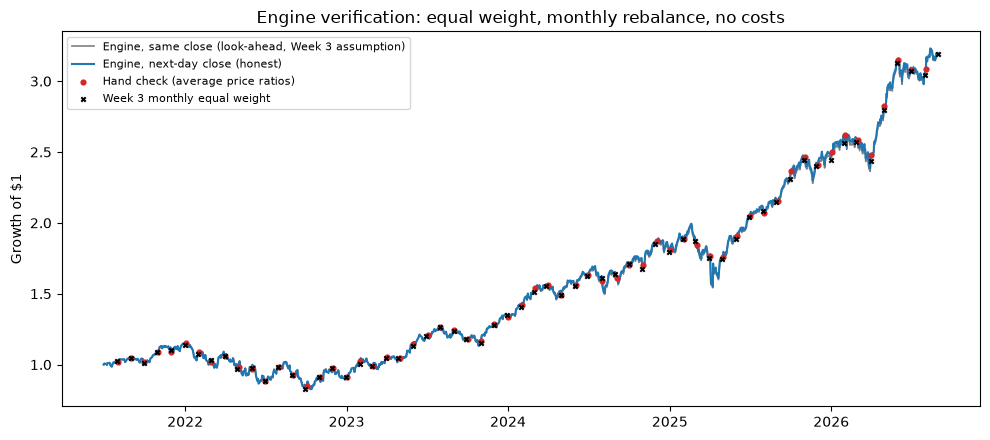

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(same_close.daily["nav"].loc[:w3.index[-1]], color="gray", lw=1.2, label="Engine, same close (look-ahead, Week 3 assumption)")
ax.plot(ew.daily["nav"].loc[:w3.index[-1]], color="C0", lw=1.5, label="Engine, next-day close (honest)")
ax.scatter(hand.index, hand.values, s=12, color="C3", zorder=3, label="Hand check (average price ratios)")
ax.scatter(w3.index, (1 + w3).cumprod().values, s=10, marker="x", color="black", zorder=3, label="Week 3 monthly equal weight")
ax.set_ylabel("Growth of $1")
ax.set_title("Engine verification: equal weight, monthly rebalance, no costs")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{REPORTS}/engine_verification.png", dpi=150)
plt.show()

### 1.9 Edge cases, tested on purpose
A copy of the prices with four problems planted, to show each policy working:
- **Untradable target:** AAPL has no price on the first execution day (1 July 2021).
- **Frozen name:** NVDA has no price on the 1 March 2022 execution day.
- **Delisting:** INTC's prices stop after 15 June 2023.
- **Stale price:** KO has no price for 8 trading days in May 2024.

Plus the real **new entrants**: PLTR and RKLB, which listed in 2020–21 and join once they have about a year of history.

In [7]:
test = px.copy()
test.loc["2021-07-01", "AAPL"] = np.nan
test.loc["2022-03-01", "NVDA"] = np.nan
test.loc["2023-06-16":, "INTC"] = np.nan
test.loc["2024-05-06":"2024-05-15", "KO"] = np.nan
test_targets = equal_weight_targets(test, signal_dates)
edge = run_backtest(test, test_targets, BacktestConfig(exec_lag=1))

print("Events recorded by the engine:")
display(edge.events.set_index(["date", "ticker", "event"]).round(4))
print("Rebalance diagnostics on the two affected execution days:")
display(edge.rebalances.set_index("exec_date").loc[["2021-07-01", "2022-03-01"],
        ["names_held", "untradable target weight", "frozen weight", "cash_weight"]].round(4))
print("Around INTC's last price (cash appears the day after):")
display(edge.daily.loc["2023-06-14":"2023-06-20", ["net_return", "cash_weight", "names_held"]].round(5))
print("INTC target weight at every signal after it stops trading:", test_targets.loc["2023-06-16":, "INTC"].max())

entry = ew.holdings.groupby("ticker")["exec_date"].min()
print("New entrants, first execution date held:", {t: f"{entry[t]:%Y-%m-%d}" for t in ["PLTR", "RKLB"]},
      "| listed:", {"PLTR": "2020-09-30", "RKLB": LISTING_DATES["RKLB"]})

Events recorded by the engine:


,,,weight moved to cash
date,ticker,event,
2022-03-01,NVDA,frozen (no price on execution day),0.0000
2023-06-16,INTC,delisted,0.0219
2024-05-13,KO,stale price,0.0196


Rebalance diagnostics on the two affected execution days:


,names_held,untradable target weight,frozen weight,cash_weight
exec_date,,,,
2021-07-01,47,0.0208,0.0000,0.0208
2022-03-01,49,0.0000,0.0216,0.0000


Around INTC's last price (cash appears the day after):


,net_return,cash_weight,names_held
date,,,
2023-06-14,0.00348,0.00000,50
2023-06-15,0.00990,0.00000,50
2023-06-16,-0.00679,0.02191,49
2023-06-20,-0.00618,0.02204,49


INTC target weight at every signal after it stops trading: 0.0
New entrants, first execution date held: {'PLTR': '2021-10-01', 'RKLB': '2022-09-01'} | listed: {'PLTR': '2020-09-30', 'RKLB': '2021-08-25'}


### 1.10 Notes
- **Engine:** `run_backtest()` in `src/backtest.py` simulates the portfolio day by day: positions drift with their own returns, and on execution days the portfolio trades from its drifted weights to the targets at the close, charges costs, and records holdings, trades and diagnostics.
- **Execution:** signals from the close of day *t* trade at the close of day *t + 1*; same-close trading is refused unless explicitly allowed.
- **Hand check:** the engine's NAV equals the buy-and-hold average of price ratios on all 61 later execution dates (difference at the level of rounding error).
- **Benchmark reconciliation:** under Week 3's same-close assumption the engine reproduces all 62 Week 3 monthly returns exactly (largest difference about 1e-15). Trading one day later moves monthly returns by 7 bp on average and leaves CAGR almost unchanged (25.2% either way), because equal weight does not depend on the latest prices; for faster signals such as momentum the lag can matter more. The honest next-day version is the one used from here on.
- **Edge cases:** untradable targets go to cash, names without a price on an execution day are frozen, delisted and long-stale names are sold into cash at their last price, and new listings enter only after about a year of history; each case is recorded in the events and diagnostics.
- **Survivorship:** our 50 stocks are today's large caps, and none actually delisted in the sample, so the delisting rule is tested on planted data only; a real universe would need delisting returns (often negative) rather than the last price.